In [5]:
import numpy as np 
import sklearn
print(np.__version__,sklearn.__version__)      

2.5.4 1.9.1


In [20]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
np.random.seed(42)
X,y=make_moons(n_samples=500,noise=0.2,random_state=42)
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42,stratify=y
)
y_train=y_train.reshape(-1,1)
y_test=y_test.reshape(-1,1)
print(X_train.shape,y_train.shape)


(400, 2) (400, 1)


In [18]:
def init_params():
    W1=np.random.randn(2,4)*0.1
    b1=np.zeros(4)
    W2=np.random.randn(4,1)*0.1
    b2=np.zeros(1)
    return W1,b1,W2,b2
W1,b1,W2,b2=init_params()
print(X_train.shape,W1.shape)
print(W1.shape,b1.shape,W2.shape,b2.shape)

(400, 2) (2, 4)
(2, 4) (4,) (4, 1) (1,)


In [9]:
def relu(z):
    return np.maximum(0,z)
def sigmoid(z):
    return 1/(1+np.exp(-z))

In [26]:
def forward(X,W1,b1,W2,b2):
    Z1=X@W1 +b1
    A1=relu(Z1)
    Z2=A1@W2+b2
    A2=sigmoid(Z2)
    return A2,(Z1,A1,Z2)
A2,cache =forward(X_train,W1,b1,W2,b2)
print(cache[0].shape,cache[1].shape,cache[2].shape,A2.shape)
print(y_train.shape,A2.min(),A2.max())


(400, 4) (400, 4) (400, 1) (400, 1)
(400, 1) 0.49108485141747027 0.5018450301330571


In [27]:
def compute_loss(A2,y):
    m=y.shape[0]
    A2=np.clip(A2,1e-8,1-1e-8)
    loss=-(1/m)*np.sum(y*np.log(A2)+(1-y)*np.log(1-A2))
    return loss
print(compute_loss(A2,y_train))

0.6963610596497409


In [29]:
def backward(X,y,cache,W2,A2):
    Z1,A1,Z2=cache
    m=X.shape[0]
    dZ2=A2-y 
    dW2=(A1.T@dZ2)/m
    db2=np.sum(dZ2,axis=0)/m 
    dA1=dZ2@W2.T
    dZ1=dA1 * (Z1 > 0) 
    dW1=(X.T @ dZ1) / m  
    db1=np.sum(dZ1,axis=0)/m
    return dW1,db1,dW2,db2
dW1,db1,dW2,db2=backward(X_train,y_train,cache,W2,A2)
print(dW1.shape,db1.shape,dW2.shape,db2.shape)

(2, 4) (4,) (4, 1) (1,)


In [30]:
def train(X,y,epochs=2000,lr=0.5):
    W1,b1,W2,b2=init_params()
    losses=[]
    for i in range(epochs):
        A2,cache=forward(X,W1,b1,W2,b2)
        loss=compute_loss(A2,y)
        losses.append(loss)
        dW1,db1,dW2,db2=backward(X,y,cache,W2,A2)
        W1=W1-lr*dW1
        b1=b1-lr*db1
        W2=W2-lr*dW2
        b2=b2-lr*db2
        if i%200==0:
            print(i,loss)
    return W1,b1,W2,b2,losses
W1,b1,W2,b2,losses=train(X_train,y_train)

0 0.6937565721385406
200 0.27775976257410806
400 0.27740103936257643
600 0.27732130245758746
800 0.27729339077261755
1000 0.2772806565024584
1200 0.277271748243034
1400 0.2772655423516026
1600 0.2772601424446228
1800 0.2772559682679225


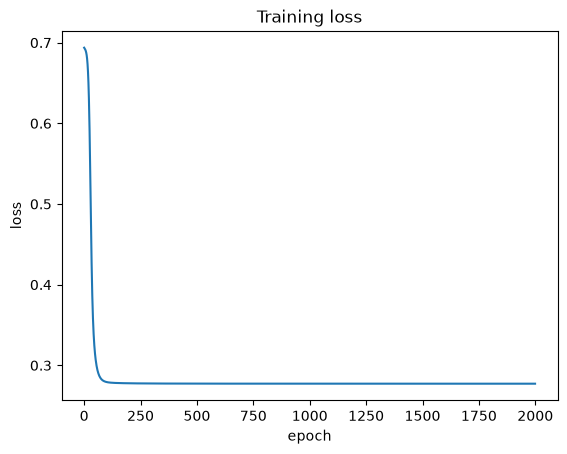

In [46]:
import matplotlib.pyplot as plt
plt.plot(losses)
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("Training loss")
plt.savefig("loss_curve.png")
plt.show()

In [36]:
def predict(X,W1,b1,W2,b2):
    A2,_=forward(X,W1,b1,W2,b2)
    labels=(A2>0.5).astype(int)
    return labels
pred=predict(X_test,W1,b1,W2,b2)
print("test accuracy:",np.mean(pred==y_test))
print(pred.shape,y_test.shape)

test accuracy: 0.86
(100, 1) (100, 1)


In [45]:
eps=1e-5
gW1,gb1,gW2,gb2=init_params()
A2,cache=forward(X_train,gW1,gb1,gW2,gb2)
dW1,db1,dW2,db2=backward(X_train,y_train,cache,gW2,A2)
num_dW1=np.zeros_like(gW1)
for i in range(gW1.shape[0]):
    for j in range(gW1.shape[1]):
        old=gW1[i,j]
        gW1[i,j]=old+eps
        A2_plus,_=forward(X_train,gW1,gb1,gW2,gb2)
        loss_plus=compute_loss(A2_plus,y_train)
        gW1[i,j]=old-eps
        A2_minus,_=forward(X_train,gW1,gb1,gW2,gb2)
        loss_minus=compute_loss(A2_minus,y_train)
        gW1[i,j]=old
        num_dW1[i,j]=(loss_plus-loss_minus)/(2*eps)
diff=np.linalg.norm(dW1-num_dW1)/(np.linalg.norm(dW1)+np.linalg.norm(num_dW1))
print("relative difference:",diff)
print(dW1)
print(num_dW1)


relative difference: 1.6258242318511328e-10
[[ 0.00060689  0.01047662 -0.00857079 -0.00559729]
 [-0.00050582 -0.01604112  0.00731374  0.01039406]]
[[ 0.00060689  0.01047662 -0.00857079 -0.00559729]
 [-0.00050582 -0.01604112  0.00731374  0.01039406]]
